# RSNA Knee Abnormality Detection — Advanced EDA Phase 3
## Data Quality, Domain Shift, Clinical NLP, Physical MRI QC, and Leakage Audit

This notebook upgrades the earlier EDA from *descriptive statistics* to **model-risk-oriented exploratory analysis**.

It is designed around the actual properties already observed in this dataset:

- 4,407 training studies and 24,371 MRI series.
- 58 gold-labeled studies; 4,349 studies with reports but no exposed target vector.
- Every study contains all three anatomical planes in the current training data.
- 159 study-level protocol fingerprints.
- MRI series range from 11 to 320 slices.
- Large differences in matrix size, pixel spacing, slice thickness, scanner vendor, and field strength.
- `Fluid_Sensitive` and `Fat_Suppression` are identical in the supplied metadata.
- Reports are multilingual and include repeated/template-like text.
- The 58 gold studies are multi-label, averaging multiple positive abnormalities per examination.

## New EDA ideas added here

1. **Adversarial validation / domain classification**
   - Can a model tell gold studies from unlabeled studies?
   - If yes, which metadata/report properties reveal the selection mechanism?

2. **Formal distribution-shift statistics**
   - standardized mean difference,
   - Kolmogorov–Smirnov statistic,
   - Wasserstein distance,
   - Jensen–Shannon divergence,
   - categorical association.

3. **Physical-space MRI features**
   - field of view in mm,
   - approximate stack coverage,
   - through-plane / in-plane anisotropy,
   - acquisition density,
   - protocol entropy.

4. **DICOM provenance and nuisance-factor audit**
   - manufacturer/model,
   - sequence descriptions,
   - laterality tags,
   - optional station/institution proxies,
   - orientation availability.

5. **Stack geometry QC on sampled complete series**
   - duplicate physical positions,
   - irregular spacing,
   - missing orientation,
   - order disagreement.

6. **Representative-slice image-quality audit**
   - contrast,
   - entropy,
   - foreground fraction,
   - edge energy,
   - clipping,
   - blank / unusual representative slices.

7. **Advanced report EDA**
   - multilingual section structure,
   - negation,
   - uncertainty,
   - severity,
   - target-definition cue coverage,
   - exact and near-duplicate reports.

8. **Unsupervised text embeddings**
   - character n-gram TF-IDF,
   - latent semantic analysis (Truncated SVD),
   - UMAP when installed, PCA fallback,
   - clustering and nearest-neighbor report audit.

9. **Cleanlab-style dataset issue detection**
   - optional Cleanlab Datalab when available,
   - built-in kNN fallback for outliers and near duplicates.

10. **Fold-risk table**
    - creates domain clusters / nuisance groups that can later be used when designing leakage-safe CV.

### Research / framework ideas that motivated these checks

- MONAI medical-image data analysis concepts.
- Deepchecks domain-classifier and image-property drift methodology.
- Evidently distribution-drift methodology.
- Cleanlab Datalab issue discovery using embeddings.
- UMAP for nonlinear manifold visualization.
- Multilingual report embeddings / clinical information extraction ideas.
- Radiology report entity, negation, uncertainty and severity analysis.

**This notebook still does not create the final pseudo-labels or train the competition model.**

In [5]:
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
import os, re, math, json, warnings, hashlib, unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom

from scipy import stats
from scipy.spatial.distance import jensenshannon
from scipy.ndimage import sobel

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 150)
pd.set_option("display.max_colwidth", 180)

SEED = 2026
rng = np.random.default_rng(SEED)

TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]

print("Core imports ready.")

Core imports ready.


## 1. Detect useful optional EDA packages

In [6]:
OPTIONAL_PACKAGES = [
    "cleanlab",
    "umap",
    "ydata_profiling",
    "deepchecks",
    "evidently",
    "monai",
    "sentence_transformers",
    "hdbscan",
]

package_status = {}
for pkg in OPTIONAL_PACKAGES:
    try:
        mod = __import__(pkg)
        package_status[pkg] = getattr(mod, "__version__", "installed")
    except Exception:
        package_status[pkg] = None

display(pd.DataFrame({
    "package": list(package_status),
    "version_or_status": [package_status[k] for k in package_status]
}))

print(
    "\nThe notebook has built-in fallbacks, so none of these packages "
    "is required for the core EDA."
)

,package,version_or_status
0,cleanlab,None
1,umap,0.5.12
2,ydata_profiling,4.18.4
3,deepchecks,None
4,evidently,None
5,monai,None
6,sentence_transformers,5.4.1
7,hdbscan,installed



The notebook has built-in fallbacks, so none of these packages is required for the core EDA.


## 2. Locate competition data and previous EDA caches

In [7]:
CANDIDATES = [
    Path("/kaggle/input/competitions/rsna-knee-abnormality-detection"),
    Path("/kaggle/input/rsna-knee-abnormality-detection"),
]
DATA_DIR = next((p for p in CANDIDATES if p.exists()), None)

if DATA_DIR is None:
    matches = list(Path("/kaggle/input").rglob("rsna-knee-abnormality-detection"))
    DATA_DIR = matches[0] if matches else None

if DATA_DIR is None:
    raise FileNotFoundError("RSNA competition data not found.")

train = pd.read_csv(DATA_DIR / "train.csv")
train_series = pd.read_csv(DATA_DIR / "train_series.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
test_series = pd.read_csv(DATA_DIR / "test_series.csv")

train["n_labels_available"] = train[TARGETS].notna().sum(axis=1)
train["is_gold"] = train["n_labels_available"].eq(len(TARGETS))

def find_cache(filename):
    candidates = [
        Path("/kaggle/working") / filename,
        DATA_DIR / filename,
    ]
    for p in candidates:
        if p.exists():
            return p
    matches = list(Path("/kaggle/input").rglob(filename))
    return matches[0] if matches else None

SERIES_CACHE = find_cache("rsna_series_inventory.csv")
STUDY_CACHE = find_cache("rsna_study_eda_features.csv")

print("Competition root:", DATA_DIR)
print("Series cache:", SERIES_CACHE)
print("Study cache:", STUDY_CACHE)
print("Train studies:", len(train), "| gold:", int(train["is_gold"].sum()))
print("Train series:", len(train_series))

Competition root: /kaggle/input/competitions/rsna-knee-abnormality-detection
Series cache: None
Study cache: None
Train studies: 4407 | gold: 58
Train series: 24371


## 3. Build / load extended DICOM series inventory

The previous inventory already contained the main geometry.  
This upgraded inventory adds several **nuisance/provenance** fields for EDA.

**Important:** fields such as `StationName` or `InstitutionName`, when present, are inspected only to understand domain structure and potential leakage. They should not automatically become model features.

In [8]:
ADV_INV_PATH = Path("/kaggle/working/rsna_advanced_series_inventory.csv")

def safe_float(x):
    try:
        return float(x)
    except Exception:
        return np.nan

def safe_mv(x):
    try:
        return "|".join(str(v) for v in x)
    except Exception:
        return str(x) if x is not None else ""

def inspect_one_series(r, split):
    study = str(r.StudyInstanceUID)
    series = str(r.SeriesInstanceUID)
    folder = DATA_DIR / f"{split}_series" / study / series

    try:
        files = [p for p in folder.iterdir() if p.is_file()]
    except Exception as e:
        return {
            "split": split, "StudyInstanceUID": study,
            "SeriesInstanceUID": series, "error": type(e).__name__
        }

    if not files:
        return {
            "split": split, "StudyInstanceUID": study,
            "SeriesInstanceUID": series, "n_files": 0, "error": "empty"
        }

    try:
        ds = pydicom.dcmread(str(files[0]), stop_before_pixels=True)
    except Exception as e:
        return {
            "split": split, "StudyInstanceUID": study,
            "SeriesInstanceUID": series, "n_files": len(files),
            "error": "dicom_" + type(e).__name__
        }

    ps = getattr(ds, "PixelSpacing", None)
    ps0 = safe_float(ps[0]) if ps is not None and len(ps) >= 1 else np.nan
    ps1 = safe_float(ps[1]) if ps is not None and len(ps) >= 2 else np.nan

    return {
        "split": split,
        "StudyInstanceUID": study,
        "SeriesInstanceUID": series,
        "Anatomical_Plane": r.Anatomical_Plane,
        "Fluid_Sensitive": int(r.Fluid_Sensitive),
        "Fat_Suppression": int(r.Fat_Suppression),
        "n_files": len(files),
        "Rows": safe_float(getattr(ds, "Rows", np.nan)),
        "Columns": safe_float(getattr(ds, "Columns", np.nan)),
        "PixelSpacingRow": ps0,
        "PixelSpacingCol": ps1,
        "SliceThickness": safe_float(getattr(ds, "SliceThickness", np.nan)),
        "SpacingBetweenSlices": safe_float(getattr(ds, "SpacingBetweenSlices", np.nan)),
        "Manufacturer": str(getattr(ds, "Manufacturer", "")).strip(),
        "ManufacturerModelName": str(getattr(ds, "ManufacturerModelName", "")).strip(),
        "MagneticFieldStrength": safe_float(getattr(ds, "MagneticFieldStrength", np.nan)),
        "RepetitionTime": safe_float(getattr(ds, "RepetitionTime", np.nan)),
        "EchoTime": safe_float(getattr(ds, "EchoTime", np.nan)),
        "FlipAngle": safe_float(getattr(ds, "FlipAngle", np.nan)),
        "SeriesDescription": str(getattr(ds, "SeriesDescription", "")).strip(),
        "SequenceName": str(getattr(ds, "SequenceName", "")).strip(),
        "ScanningSequence": safe_mv(getattr(ds, "ScanningSequence", "")),
        "SequenceVariant": safe_mv(getattr(ds, "SequenceVariant", "")),
        "ScanOptions": safe_mv(getattr(ds, "ScanOptions", "")),
        "Laterality": str(getattr(ds, "Laterality", "")).strip(),
        "ImageLaterality": str(getattr(ds, "ImageLaterality", "")).strip(),
        "PatientPosition": str(getattr(ds, "PatientPosition", "")).strip(),
        "InstitutionName": str(getattr(ds, "InstitutionName", "")).strip(),
        "StationName": str(getattr(ds, "StationName", "")).strip(),
        "ImageOrientationPatient": safe_mv(getattr(ds, "ImageOrientationPatient", "")),
        "ImagePositionPatient": safe_mv(getattr(ds, "ImagePositionPatient", "")),
        "PhotometricInterpretation": str(getattr(ds, "PhotometricInterpretation", "")).strip(),
        "BitsStored": safe_float(getattr(ds, "BitsStored", np.nan)),
        "error": "",
    }

if ADV_INV_PATH.exists():
    inv = pd.read_csv(ADV_INV_PATH)
    print("Loaded cached advanced inventory.")
else:
    jobs = []
    rows = []
    with ThreadPoolExecutor(max_workers=12) as ex:
        for r in train_series.itertuples(index=False):
            jobs.append(ex.submit(inspect_one_series, r, "train"))
        for r in test_series.itertuples(index=False):
            jobs.append(ex.submit(inspect_one_series, r, "test"))

        for i, fut in enumerate(as_completed(jobs), 1):
            rows.append(fut.result())
            if i % 2500 == 0:
                print(f"Inspected {i:,}/{len(jobs):,} series")

    inv = pd.DataFrame(rows)
    inv.to_csv(ADV_INV_PATH, index=False)
    print("Saved:", ADV_INV_PATH)

train_inv = inv[inv["split"].eq("train")].copy()
test_inv = inv[inv["split"].eq("test")].copy()

print("Inventory rows:", len(inv))
print("Header-read errors:", int(inv["error"].fillna("").ne("").sum()))
display(train_inv.head())

Loaded cached advanced inventory.
Inventory rows: 24386
Header-read errors: 0


,split,StudyInstanceUID,SeriesInstanceUID,Anatomical_Plane,Fluid_Sensitive,Fat_Suppression,n_files,Rows,Columns,PixelSpacingRow,PixelSpacingCol,SliceThickness,SpacingBetweenSlices,Manufacturer,ManufacturerModelName,MagneticFieldStrength,RepetitionTime,EchoTime,FlipAngle,SeriesDescription,SequenceName,ScanningSequence,SequenceVariant,ScanOptions,Laterality,ImageLaterality,PatientPosition,InstitutionName,StationName,ImageOrientationPatient,ImagePositionPatient,PhotometricInterpretation,BitsStored,error
0,train,1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585,1.2.826.0.1.3680043.8.498.27845969797953115400959653384511165237,Sagittal,0,0,34,768.0,768.0,0.221400,0.221400,2.5,3.000,Siemens Healthineers,MAGNETOM Vida,3.0,2200.000000,32.0,180.0,int_tse_sag_p3_s2_2.5mm_drb_384,*tseR2d1_9,S|E,SP|SK,SP|PER,R,NaN,FFS,NaN,NaN,-0.00018944|0.999993|0.00383791|-0.0306549|0.0038303|-0.999523,-90.1294|-96.4204|26.7742,MONOCHROME2,12.0,NaN
1,train,1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,1.2.826.0.1.3680043.8.498.75714899997203615784077798038670363546,Sagittal,0,0,22,640.0,640.0,0.264062,0.264062,3.0,4.635,Philips Healthcare,Ingenia,1.5,3493.437256,10.0,90.0,DP CS_SAG,NaN,S|E,S|K,O|T|H|E|R,NaN,NaN,FFS,NaN,NaN,-0.0334932804107|0.99921125173568|0.02133215218782|0.05801957845687|0.02325204573571|-0.9980446100234,-113.33504963526|-144.19748338321|96.6729347740064,MONOCHROME2,12.0,NaN
2,train,1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,1.2.826.0.1.3680043.8.498.23084836536722595275828690293168736174,Coronal,0,0,16,576.0,576.0,0.298910,0.298910,4.0,6.595,Philips Healthcare,Ingenia,1.5,643.492004,15.0,90.0,T1_TSE_CS,NaN,S|E,S|K,O|T|H|E|R,NaN,NaN,FFS,NaN,NaN,0.99682223796844|-0.0789138898253|-0.0108658866956|-0.0051275272853|0.07255844771862|-0.9973509907722,-192.948080965|-81.338004975119|97.4662143047532,MONOCHROME2,12.0,NaN
3,train,1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265,Axial,1,1,18,560.0,560.0,0.287712,0.287712,4.0,7.718,Philips Healthcare,Ingenia,1.5,2599.101074,20.0,90.0,STIR CS_ AX,NaN,I|R,S|K,O|T|H|E|R,NaN,NaN,FFS,NaN,NaN,0.99478304386138|-0.1011089235544|0.01355419494211|0.09998968243598|0.99273771047592|0.06688710302114,-194.59868525548|-129.3774862109|-38.74289354102,MONOCHROME2,12.0,NaN
4,train,1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585,1.2.826.0.1.3680043.8.498.87374594163896635184044513927478147680,Coronal,0,0,30,640.0,540.0,0.250000,0.250000,3.0,3.600,Siemens Healthineers,MAGNETOM Vida,3.0,684.000000,12.0,180.0,t1_tse_cor_s2p2_448_DRB,*tse2d1_3,S|E,SP|SK,P|E|R,R,NaN,FFS,NaN,NaN,0.999541|-0.000289172|-0.0302993|-0.0300255|0.124995|-0.991703,-144.419|-19.7255|24.6017,MONOCHROME2,12.0,NaN


## 4. Derive physical MRI acquisition features

In [9]:
eps = 1e-8

for df in [train_inv, test_inv]:
    df["FOV_Row_mm"] = df["Rows"] * df["PixelSpacingRow"]
    df["FOV_Col_mm"] = df["Columns"] * df["PixelSpacingCol"]

    through_spacing = df["SpacingBetweenSlices"].copy()
    through_spacing = through_spacing.fillna(df["SliceThickness"])

    df["ApproxStackCoverage_mm"] = df["n_files"] * through_spacing
    df["InPlaneMean_mm"] = (df["PixelSpacingRow"] + df["PixelSpacingCol"]) / 2
    df["AnisotropyRatio"] = through_spacing / (df["InPlaneMean_mm"] + eps)
    df["MatrixAspect"] = df["Columns"] / (df["Rows"] + eps)
    df["PhysicalAspect"] = df["FOV_Col_mm"] / (df["FOV_Row_mm"] + eps)
    df["ApproxVoxelVolume_mm3"] = (
        df["PixelSpacingRow"] *
        df["PixelSpacingCol"] *
        through_spacing
    )

physical_cols = [
    "FOV_Row_mm","FOV_Col_mm","ApproxStackCoverage_mm",
    "InPlaneMean_mm","AnisotropyRatio","MatrixAspect",
    "PhysicalAspect","ApproxVoxelVolume_mm3"
]

display(train_inv[physical_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
FOV_Row_mm,24371.0,163.705713,15.663704,70.327194,159.999996,160.000005,170.000000,320.000000
FOV_Col_mm,24371.0,164.719479,22.553022,70.327194,159.772051,160.000005,170.000000,361.000000
ApproxStackCoverage_mm,24371.0,107.985401,20.187391,23.100000,98.000000,105.600000,118.800000,240.000000
InPlaneMean_mm,24371.0,0.339234,0.124015,0.072807,0.250000,0.312500,0.390625,1.171875
AnisotropyRatio,24371.0,12.152847,5.034435,0.640000,8.448000,11.840000,14.519999,39.443005
MatrixAspect,24371.0,1.006801,0.107406,0.500000,1.000000,1.000000,1.000000,2.000000
PhysicalAspect,24371.0,1.006801,0.107406,0.500000,1.000000,1.000000,1.000000,2.000000
ApproxVoxelVolume_mm3,24371.0,0.472393,0.374174,0.013655,0.217529,0.402605,0.572918,3.543511


## 5. Physical-space outlier audit

Robust z-scores use the median and MAD, which are less sensitive to extreme acquisition values than ordinary mean/std z-scores.

In [10]:
def robust_z(x):
    x = pd.to_numeric(x, errors="coerce")
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    if not np.isfinite(mad) or mad < 1e-12:
        return pd.Series(np.zeros(len(x)), index=x.index)
    return 0.67448975 * (x - med) / mad

for col in physical_cols + ["n_files","Rows","Columns","SliceThickness"]:
    train_inv[f"rz_{col}"] = robust_z(train_inv[col])

rz_cols = [c for c in train_inv.columns if c.startswith("rz_")]
train_inv["physical_outlier_score"] = train_inv[rz_cols].abs().max(axis=1)

display(
    train_inv.nlargest(30, "physical_outlier_score")[
        ["StudyInstanceUID","SeriesInstanceUID","Anatomical_Plane",
         "Manufacturer","MagneticFieldStrength","n_files","Rows","Columns",
         "PixelSpacingRow","SliceThickness","FOV_Row_mm",
         "ApproxStackCoverage_mm","AnisotropyRatio","physical_outlier_score"]
    ]
)

,StudyInstanceUID,SeriesInstanceUID,Anatomical_Plane,Manufacturer,MagneticFieldStrength,n_files,Rows,Columns,PixelSpacingRow,SliceThickness,FOV_Row_mm,ApproxStackCoverage_mm,AnisotropyRatio,physical_outlier_score
4573,1.2.826.0.1.3680043.8.498.12377852033407536077897684568488365785,1.2.826.0.1.3680043.8.498.24380565001952303917864952593178583464,Axial,Siemens Healthineers,1.5,160,640.0,1280.0,0.251563,0.6,161.00032,96.0,2.385088,1.834651e+11
7305,1.2.826.0.1.3680043.8.498.16724013341359693140331158148551346369,1.2.826.0.1.3680043.8.498.25592896488543437051375167420950620443,Axial,Siemens Healthineers,1.5,144,640.0,1280.0,0.251563,0.6,161.00032,86.4,2.385088,1.834651e+11
526,1.2.826.0.1.3680043.8.498.10243300429607935614655219482457289307,1.2.826.0.1.3680043.8.498.11813424485012618176922849479597231956,Axial,Siemens Healthineers,1.5,144,640.0,1280.0,0.250000,0.6,160.00000,86.4,2.400000,1.834651e+11
565,1.2.826.0.1.3680043.8.498.10261794102024899290234062909324134903,1.2.826.0.1.3680043.8.498.24268032675274956886789362244354592047,Axial,Siemens Healthineers,1.5,160,640.0,1280.0,0.250000,0.6,160.00000,96.0,2.400000,1.834651e+11
660,1.2.826.0.1.3680043.8.498.10318366890716843554246682186865048846,1.2.826.0.1.3680043.8.498.10812668322490503397843861888978525173,Axial,Siemens Healthineers,1.5,128,640.0,1280.0,0.250000,0.6,160.00000,76.8,2.400000,1.834651e+11
781,1.2.826.0.1.3680043.8.498.10371162371589200772388569623043753617,1.2.826.0.1.3680043.8.498.23096471439003297465310065770422966179,Axial,Siemens Healthineers,1.5,160,640.0,1280.0,0.250000,0.6,160.00000,96.0,2.400000,1.834651e+11
885,1.2.826.0.1.3680043.8.498.10423586531262405323219596291234698626,1.2.826.0.1.3680043.8.498.53636053019000465981833059248294288955,Axial,Siemens Healthineers,1.5,144,640.0,1280.0,0.250000,0.6,160.00000,86.4,2.400000,1.834651e+11
910,1.2.826.0.1.3680043.8.498.10434135978927658622039675788413759069,1.2.826.0.1.3680043.8.498.11798306767994349595961889415922717610,Axial,Siemens Healthineers,1.5,144,640.0,1280.0,0.250000,0.6,160.00000,86.4,2.400000,1.834651e+11
957,1.2.826.0.1.3680043.8.498.10459044164648238749799867924228983674,1.2.826.0.1.3680043.8.498.97639855332563872908207073072676858618,Axial,Siemens Healthineers,1.5,144,640.0,1280.0,0.250000,0.6,160.00000,86.4,2.400000,1.834651e+11
1029,1.2.826.0.1.3680043.8.498.10499265498716562276605625682538326716,1.2.826.0.1.3680043.8.498.86750785011951108457240770736567788192,Axial,Siemens Healthineers,1.5,160,640.0,1280.0,0.250000,0.6,160.00000,96.0,2.400000,1.834651e+11


## 6. Protocol completeness and redundancy

In [11]:
protocol = (
    train_series.groupby("StudyInstanceUID")
    .agg(
        n_series=("SeriesInstanceUID","size"),
        n_planes=("Anatomical_Plane","nunique"),
        n_fluid=("Fluid_Sensitive","sum"),
        n_fatsupp=("Fat_Suppression","sum"),
    )
)

for plane in ["Sagittal","Coronal","Axial"]:
    protocol[f"n_{plane.lower()}"] = (
        train_series["Anatomical_Plane"].eq(plane)
        .groupby(train_series["StudyInstanceUID"])
        .sum()
    )

print("Studies missing at least one standard plane:",
      int((protocol["n_planes"] < 3).sum()))
print("Fluid/FatSupp row disagreement:",
      int((train_series["Fluid_Sensitive"] != train_series["Fat_Suppression"]).sum()))
print("Unique protocol rows:",
      protocol.astype(str).agg("|".join, axis=1).nunique())

display(protocol.describe())

Studies missing at least one standard plane: 0
Fluid/FatSupp row disagreement: 0
Unique protocol rows: 135


,n_series,n_planes,n_fluid,n_fatsupp,n_sagittal,n_coronal,n_axial
count,4407.000000,4407.0,4407.000000,4407.000000,4407.000000,4407.000000,4407.000000
mean,5.530066,3.0,3.179033,3.179033,2.238257,1.953483,1.338325
std,1.393826,0.0,0.634130,0.634130,0.595381,0.748044,0.658158
min,3.000000,3.0,2.000000,2.000000,1.000000,1.000000,1.000000
25%,5.000000,3.0,3.000000,3.000000,2.000000,1.000000,1.000000
50%,5.000000,3.0,3.000000,3.000000,2.000000,2.000000,1.000000
75%,6.000000,3.0,3.000000,3.000000,2.000000,2.000000,1.000000
max,14.000000,3.0,7.000000,7.000000,6.000000,5.000000,7.000000


## 7. Sequence-description vocabulary

The organizer already supplied plane/fluid labels, but raw DICOM sequence descriptions may reveal additional protocol families (PD, T1, T2, STIR, etc.).

These fields are useful for **EDA and protocol clustering**, but do not automatically treat scanner-specific naming conventions as disease features.

In [12]:
def normalize_seq_text(s):
    s = str(s).casefold()
    s = unicodedata.normalize("NFKD", s)
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    s = re.sub(r"\d+(\.\d+)?", " # ", s)
    s = re.sub(r"[^a-z#]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()

train_inv["SequenceText"] = (
    train_inv["SeriesDescription"].fillna("") + " " +
    train_inv["SequenceName"].fillna("") + " " +
    train_inv["ScanningSequence"].fillna("") + " " +
    train_inv["ScanOptions"].fillna("")
).map(normalize_seq_text)

token_counts = Counter()
for s in train_inv["SequenceText"]:
    token_counts.update([t for t in s.split() if len(t) >= 2])

display(pd.DataFrame(token_counts.most_common(80), columns=["token","count"]))

,token,count
0,gems,23660
1,tse,16288
2,fs,13481
3,sag,7381
4,pd,7160
...,...,...
75,tir,82
76,tirm,80
77,der,80
78,hypersense,77


## 8. Study-level nuisance/domain table

This aggregates scanner + protocol information at the examination level.

In [13]:
def safe_mode(s):
    s = s.fillna("").astype(str)
    s = s[s.ne("")]
    m = s.mode()
    return m.iloc[0] if len(m) else ""

study_domain = (
    train_inv.groupby("StudyInstanceUID")
    .agg(
        manufacturer=("Manufacturer", safe_mode),
        model=("ManufacturerModelName", safe_mode),
        field_strength=("MagneticFieldStrength","median"),
        median_slices=("n_files","median"),
        max_slices=("n_files","max"),
        median_fov=("FOV_Row_mm","median"),
        median_inplane=("InPlaneMean_mm","median"),
        median_anisotropy=("AnisotropyRatio","median"),
        median_thickness=("SliceThickness","median"),
        n_series_inv=("SeriesInstanceUID","size"),
    )
    .join(protocol, how="left")
    .reset_index()
)

display(study_domain.head())

,StudyInstanceUID,manufacturer,model,field_strength,median_slices,max_slices,median_fov,median_inplane,median_anisotropy,median_thickness,n_series_inv,n_series,n_planes,n_fluid,n_fatsupp,n_sagittal,n_coronal,n_axial
0,1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,Philips Healthcare,Ingenia,1.5,18.0,22,169.000000,0.298910,21.450611,4.0,5,5,3,3,3,2,2,1
1,1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585,Siemens Healthineers,MAGNETOM Vida,3.0,34.0,38,160.000000,0.234400,14.399999,3.0,5,5,3,3,3,2,2,1
2,1.2.826.0.1.3680043.8.498.10009278692606631573540062909909132231,Siemens Healthineers,MAGNETOM Lumina,3.0,38.0,48,179.999872,0.432692,6.933338,2.5,5,5,3,3,3,2,2,1
3,1.2.826.0.1.3680043.8.498.10009639203170750274174707434356622764,SIEMENS,Aera,1.5,30.0,160,159.999996,0.333333,9.440000,3.0,10,10,3,4,4,3,4,3
4,1.2.826.0.1.3680043.8.498.10013663742400736029415768216599146542,Siemens Healthineers,MAGNETOM Aera,1.5,38.0,40,160.000128,0.416667,7.919993,3.0,5,5,3,4,4,2,1,2


## 9. Better report features: language, sections, negation, uncertainty, severity

In [14]:
# EDA-oriented language detector. It is deliberately transparent and deterministic.
# A transformer language-ID model can be plugged in later if desired.
LANG_HINTS = {
    "English": [" the "," knee "," ligament "," meniscus "," findings "," impression "," tear "," intact "],
    "Spanish": [" rodilla "," menisco "," ligamento "," hallazgos "," impresion "," rotura "," derrame "," no hay "],
    "French": [" genou "," menisque "," ligament "," constatations "," conclusion "," aucune "," epaississement "],
    "German/Dutch": [" knie "," menisk"," kreuzband"," befund"," geen "," keine "," zonder "," mit "],
    "Turkish": [" diz "," menisk"," bag"," bulgu"," izlen"," saptan"," yoktur "," eklem "],
    "Balkan-Latin": [" koljen"," kolen"," menisk"," ligament"," nema "," bez "," nalaz"],
}

def strip_accents(s):
    s = unicodedata.normalize("NFKD", str(s))
    return "".join(ch for ch in s if not unicodedata.combining(ch))

def script_group(text):
    greek = sum("\\u0370" <= ch <= "\\u03ff" for ch in text)
    cyr = sum("\\u0400" <= ch <= "\\u04ff" for ch in text)
    if greek > 10: return "Greek"
    if cyr > 10: return "Cyrillic"
    return "Latin"

def rough_language(text):
    sg = script_group(str(text))
    if sg != "Latin":
        return sg
    t = " " + strip_accents(str(text)).casefold() + " "
    scores = {
        lang: sum(t.count(strip_accents(h).casefold()) for h in hints)
        for lang, hints in LANG_HINTS.items()
    }
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else "Latin-Other"

SECTION_PATTERNS = {
    "findings": [
        r"\\bfindings?\\b", r"\\bhallazgos?\\b", r"\\bconstatations?\\b",
        r"\\bbefund\\b", r"\\bbulgular\\b", r"\\bnalaz\\b"
    ],
    "impression": [
        r"\\bimpression\\b", r"\\bconclusion\\b", r"\\bimpresion\\b",
        r"\\bbeurteilung\\b", r"\\bsonuc\\b", r"\\bzakljucak\\b"
    ],
}

NEGATION_CUES = [
    " no ", " not ", " without ", " absent ", " intact ", " preserved ",
    " normal ", " no hay ", " sin ", " ausencia ", " aucune ", " sans ",
    " kein ", " keine ", " ohne ", " geen ", " zonder ",
    " yok ", " yoktur ", " izlenmedi ", " saptanmadi ", " nema "
]

UNCERTAINTY_CUES = [
    " possible ", " possibly ", " probable ", " suspicious ", " suspect ",
    " cannot exclude ", " equivocal ", " questionable ", " indeterminate ",
    " posible ", " probable ", " sospecha ", " dudoso ",
    " moglich ", " verdacht ", " olabilir ", " supheli "
]

LOW_SEVERITY_CUES = [
    " mild ", " minimal ", " trace ", " tiny ", " small ", " low grade ",
    " leve ", " minimo ", " pequena ", " petit ", " faible ",
    " gering ", " hafif ", " minimal "
]

HIGH_SEVERITY_CUES = [
    " severe ", " high grade ", " complete ", " full thickness ",
    " greater than 50", " >50", " marked ", " large ", " moderate to large ",
    " severa ", " grave ", " completo ", " espesor total ",
    " hochgrad", " komplett", " ileri ", " tam kat "
]

def cue_count(text, cues):
    t = " " + strip_accents(str(text)).casefold().replace("\\n"," ") + " "
    return sum(t.count(strip_accents(c).casefold()) for c in cues)

rpt = train[["StudyInstanceUID","Report","is_gold"]].copy()
rpt["language"] = rpt["Report"].map(rough_language)
rpt["chars"] = rpt["Report"].fillna("").str.len()
rpt["words"] = rpt["Report"].fillna("").str.split().str.len()
rpt["lines"] = rpt["Report"].fillna("").str.count("\\n") + 1
rpt["negation_count"] = rpt["Report"].map(lambda x: cue_count(x, NEGATION_CUES))
rpt["uncertainty_count"] = rpt["Report"].map(lambda x: cue_count(x, UNCERTAINTY_CUES))
rpt["low_severity_count"] = rpt["Report"].map(lambda x: cue_count(x, LOW_SEVERITY_CUES))
rpt["high_severity_count"] = rpt["Report"].map(lambda x: cue_count(x, HIGH_SEVERITY_CUES))

for sec, pats in SECTION_PATTERNS.items():
    rx = re.compile("|".join(pats), flags=re.I)
    rpt[f"has_{sec}"] = rpt["Report"].fillna("").map(lambda x: bool(rx.search(strip_accents(x))))

display(rpt.head())
display(rpt["language"].value_counts().to_frame("studies"))

,StudyInstanceUID,Report,is_gold,language,chars,words,lines,negation_count,uncertainty_count,low_severity_count,high_severity_count,has_findings,has_impression
0,1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame. ....,False,Spanish,322,44,1,0,0,0,0,False,False
1,1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585,[DATE]: * MR Knie Rechts 15ch AA Klinische Inlichtingen: [DATE]. Diagnostische vraagstellling: Meniscusscheur/mediaal? Scanprotocol (DRB) : sag intermediair gewogen seq zonder ...,False,German/Dutch,245,35,1,1,0,0,0,False,False
2,1.2.826.0.1.3680043.8.498.10009278692606631573540062909909132231,Hallazgos:\nNo hay alteraciones en significativas de la médula ósea.\nLigamentos cruzados y colaterales dentro de límites normales.\nAumento de señal del cuerno posterior del m...,False,Spanish,1414,210,21,4,0,0,0,False,False
3,1.2.826.0.1.3680043.8.498.10009639203170750274174707434356622764,"In the medial compartment, the meniscus is not torn and there is no focal chondrosis or chondral injury. \n The lateral compartment, there is suspicious incomplete discoid lat...",False,English,1027,140,9,10,2,0,0,False,False
4,1.2.826.0.1.3680043.8.498.10013663742400736029415768216599146542,CONSTATATIONS :\n\nFractures :\nAucune.\n\nAlignement articulaire :\nNormal.\n\nChangements dégénératifs :\nChondropatie rétropatellaire modérée à sévère avec fissuration profo...,False,French,1195,162,39,2,0,0,1,False,False


,studies
language,
English,1751
Latin-Other,694
Turkish,546
Spanish,532
Balkan-Latin,446
German/Dutch,367
French,71


## 10. Challenge-specific clinical cue coverage

This is not pseudo-labeling.  
It simply asks: *how often does each report contain textual evidence related to each challenge target?*

We specifically track:
- target/anatomy mention,
- high-severity cues,
- low-severity cues,
- uncertainty,
- negation.

These matter because the organizer's labels use **specific severity thresholds** and treat borderline findings as negative.

In [15]:
TARGET_LEXICON = {
    "ACL": ["acl","anterior cruciate","cruzado anterior","lca","vkb","kreuzband"],
    "MCL": ["mcl","medial collateral","colateral medial","lcm","innenband"],
    "Medial Meniscus": ["medial meniscus","menisco medial","menisco interno","mediale menisk","medialni menisk"],
    "Lateral Meniscus": ["lateral meniscus","menisco lateral","menisco externo","laterale menisk","lateralni menisk"],
    "Medial OA": ["medial compartment","medial femorotibial","femorotibial medial","medial cartilage"],
    "Lateral OA": ["lateral compartment","lateral femorotibial","femorotibial lateral","lateral cartilage"],
    "PF OA": ["patellofemoral","patellar cartilage","trochlea","trochlear cartilage","retropatellar","rotul"],
    "Effusion": ["effusion","joint fluid","derrame","epanchement","erguss","eklem ici sivi"],
    "Synovitis": ["synovitis","sinovitis","synoviale","synovial thickening","sinovit"],
    "Baker's": ["baker","popliteal cyst","quiste poplite","kyste poplite","poplitealzyste"],
    "Contusion": ["contusion","bone bruise","bone marrow edema","marrow oedema","edema oseo","bone edema"],
    "Fracture": ["fracture","fractura","fraktur","cortical break","fracture line","kirik"],
}

def mention_count(text, terms):
    t = strip_accents(str(text)).casefold()
    return sum(t.count(strip_accents(term).casefold()) for term in terms)

coverage_rows = []
for target, terms in TARGET_LEXICON.items():
    m = rpt["Report"].map(lambda x: mention_count(x, terms))
    coverage_rows.append({
        "target": target,
        "reports_with_mention": int((m > 0).sum()),
        "mention_pct": 100 * (m > 0).mean(),
        "gold_with_mention": int(((m > 0) & rpt["is_gold"]).sum()),
    })

coverage = pd.DataFrame(coverage_rows)
display(coverage)

,target,reports_with_mention,mention_pct,gold_with_mention
0,ACL,1903,43.181302,34
1,MCL,1664,37.758112,27
2,Medial Meniscus,1625,36.873156,30
3,Lateral Meniscus,1812,41.116406,30
4,Medial OA,928,21.057409,17
5,Lateral OA,890,20.195144,15
6,PF OA,1926,43.703199,29
7,Effusion,2330,52.870433,38
8,Synovitis,462,10.483322,14
9,Baker's,1575,35.738598,19


## 11. Gold vs unlabeled — univariate shift statistics

In [16]:
study = (
    rpt.drop(columns=["Report"])
    .merge(study_domain, on="StudyInstanceUID", how="left")
)

numeric_shift_cols = [
    "chars","words","lines","negation_count","uncertainty_count",
    "low_severity_count","high_severity_count",
    "n_series","n_fluid","n_sagittal","n_coronal","n_axial",
    "field_strength","median_slices","max_slices",
    "median_fov","median_inplane","median_anisotropy","median_thickness"
]

def smd(a,b):
    a = pd.to_numeric(pd.Series(a), errors="coerce").dropna().values
    b = pd.to_numeric(pd.Series(b), errors="coerce").dropna().values
    if len(a)<2 or len(b)<2: return np.nan
    pooled = np.sqrt((np.var(a,ddof=1)+np.var(b,ddof=1))/2)
    return (np.mean(a)-np.mean(b))/pooled if pooled>0 else 0.0

rows=[]
for col in numeric_shift_cols:
    g = study.loc[study["is_gold"], col].dropna()
    u = study.loc[~study["is_gold"], col].dropna()
    if len(g) < 2 or len(u) < 2:
        continue
    ks = stats.ks_2samp(g,u)
    wd = stats.wasserstein_distance(g,u)
    rows.append({
        "feature": col,
        "gold_mean": g.mean(),
        "unlabeled_mean": u.mean(),
        "SMD": smd(g,u),
        "KS": ks.statistic,
        "KS_p": ks.pvalue,
        "Wasserstein": wd,
    })

shift_numeric = pd.DataFrame(rows)
shift_numeric["abs_SMD"] = shift_numeric["SMD"].abs()
display(shift_numeric.sort_values(["abs_SMD","KS"], ascending=False))

,feature,gold_mean,unlabeled_mean,SMD,KS,KS_p,Wasserstein,abs_SMD
1,words,179.000000,147.123477,0.312719,0.205410,0.013530,32.049897,0.312719
15,median_fov,167.254900,162.980989,0.289430,0.112301,0.433900,4.379340,0.289430
0,chars,1305.086207,1095.142562,0.284608,0.186115,0.032902,211.048727,0.284608
6,high_severity_count,0.655172,0.340998,0.276246,0.115151,0.402602,0.330270,0.276246
12,field_strength,2.250000,2.071737,0.239472,0.117440,0.444088,0.178263,0.239472
8,n_fluid,3.310345,3.177282,0.206560,0.093973,0.657419,0.151918,0.206560
5,low_severity_count,1.500000,1.063233,0.194896,0.080910,0.818023,0.439066,0.194896
7,n_series,5.793103,5.526558,0.186810,0.124983,0.306444,0.332768,0.186810
4,uncertainty_count,0.224138,0.090366,0.179594,0.033333,1.000000,0.136532,0.179594
9,n_sagittal,2.344828,2.236836,0.171427,0.110985,0.448393,0.129606,0.171427


## 12. Gold vs unlabeled — categorical shift

We inspect language, manufacturer, scanner model and field strength.

Sparse categories are collapsed to avoid unstable tables.

In [17]:
categorical_cols = ["language","manufacturer","model","field_strength"]

def collapse_rare(s, min_count=20):
    s = s.fillna("MISSING").astype(str)
    counts = s.value_counts()
    keep = set(counts[counts >= min_count].index)
    return s.where(s.isin(keep), "OTHER")

cat_shift = []
for col in categorical_cols:
    x = collapse_rare(study[col])
    table = pd.crosstab(x, study["is_gold"])
    if table.shape[0] < 2 or table.shape[1] < 2:
        continue
    chi2,p,dof,expected = stats.chi2_contingency(table)
    n = table.values.sum()
    phi2 = chi2 / max(n,1)
    r,k = table.shape
    cramers_v = np.sqrt(phi2 / max(min(k-1,r-1),1))
    cat_shift.append({
        "feature": col,
        "levels": table.shape[0],
        "chi2": chi2,
        "p": p,
        "cramers_v": cramers_v,
    })
    print("\n", col)
    display(table)

display(pd.DataFrame(cat_shift).sort_values("cramers_v", ascending=False))


 language


is_gold,False,True
language,,
Balkan-Latin,441,5
English,1723,28
French,71,0
German/Dutch,364,3
Latin-Other,686,8
Spanish,524,8
Turkish,540,6



 manufacturer


is_gold,False,True
manufacturer,,
CANON_MEC,44,1
GE MEDICAL SYSTEMS,852,16
GEHC,37,0
OTHER,24,0
Philips,485,7
Philips Healthcare,89,2
Philips Medical Systems,709,9
SIEMENS,793,11
Siemens,94,0



 model


is_gold,False,True
model,,
Achieva dStream,321,6
Aera,397,3
Espree,64,0
Galan 3T,44,1
Ingenia,731,10
Ingenia Ambition X,83,1
Ingenia Elition X,20,0
MAGNETOM Aera,121,1
MAGNETOM Avanto fit,260,2



 field_strength


is_gold,False,True
field_strength,,
1.16,24,0
1.5,2517,26
3.0,1575,26
MISSING,232,6
OTHER,1,0


,feature,levels,chi2,p,cramers_v
2,model,30,22.901064,0.781051,0.072087
1,manufacturer,11,6.245700,0.794215,0.037646
3,field_strength,5,5.851188,0.210541,0.036438
0,language,7,3.345010,0.764463,0.027550


# 13. Adversarial validation: can metadata identify the 58 gold studies?

This is a powerful EDA technique.

We train a classifier with **no disease labels**. Its only task is:

```text
study features → gold vs unlabeled
```

Interpretation:
- AUC ≈ 0.5: the groups are hard to distinguish with these features.
- High AUC: the 58-case gold set is selected differently and should not be treated as a simple random sample.

Because only 58 gold rows exist, this is a diagnostic, not a definitive statistical proof.

In [18]:
adv_features_num = [
    "chars","words","lines","negation_count","uncertainty_count",
    "low_severity_count","high_severity_count",
    "n_series","n_fluid","n_sagittal","n_coronal","n_axial",
    "field_strength","median_slices","max_slices",
    "median_fov","median_inplane","median_anisotropy","median_thickness"
]
adv_features_cat = ["language","manufacturer"]

adv = study[["is_gold"] + adv_features_num + adv_features_cat].copy()
for c in adv_features_num:
    adv[c] = pd.to_numeric(adv[c], errors="coerce")
    adv[c] = adv[c].fillna(adv[c].median())
for c in adv_features_cat:
    adv[c] = adv[c].fillna("MISSING").astype(str)

pre = ColumnTransformer([
    ("num", StandardScaler(), adv_features_num),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), adv_features_cat),
])

clf = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    C=0.5,
    solver="liblinear",
    random_state=SEED
)

pipe = Pipeline([("pre",pre),("clf",clf)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = cross_val_predict(
    pipe,
    adv.drop(columns="is_gold"),
    adv["is_gold"].astype(int),
    cv=cv,
    method="predict_proba"
)[:,1]

auc = roc_auc_score(adv["is_gold"].astype(int), oof)
print(f"Gold-vs-unlabeled adversarial OOF AUC: {auc:.4f}")

adv_out = study[["StudyInstanceUID","is_gold"]].copy()
adv_out["gold_selection_probability_oof"] = oof
display(adv_out.sort_values("gold_selection_probability_oof", ascending=False).head(30))

Gold-vs-unlabeled adversarial OOF AUC: 0.5598


,StudyInstanceUID,is_gold,gold_selection_probability_oof
3916,1.2.826.0.1.3680043.8.498.87064372531225943854092598173945043861,False,0.996960
3387,1.2.826.0.1.3680043.8.498.73070182506490199787361298167985971577,False,0.994793
2309,1.2.826.0.1.3680043.8.498.42942844751304929338846069579289911684,False,0.992435
2991,1.2.826.0.1.3680043.8.498.62924835279557724526138406447993672103,False,0.992238
3973,1.2.826.0.1.3680043.8.498.88620225126852321191690360547272730103,False,0.987501
1624,1.2.826.0.1.3680043.8.498.25549974159486441938843396591725289882,False,0.987054
3879,1.2.826.0.1.3680043.8.498.86042942187650835661744645315369706668,False,0.982657
3543,1.2.826.0.1.3680043.8.498.77155817997584903787597001328868124855,False,0.981607
2064,1.2.826.0.1.3680043.8.498.37040910196459054543310335064167212742,True,0.979818
976,1.2.826.0.1.3680043.8.498.12790542912560396272981117250277568532,False,0.977482


## 14. Fit adversarial model and inspect strongest selection features

In [19]:
pipe.fit(adv.drop(columns="is_gold"), adv["is_gold"].astype(int))

feature_names = pipe.named_steps["pre"].get_feature_names_out()
coefs = pipe.named_steps["clf"].coef_.ravel()

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coef": coefs,
    "abs_coef": np.abs(coefs)
}).sort_values("abs_coef", ascending=False)

display(coef_df.head(40))

,feature,coef,abs_coef
34,cat__manufacturer_Siemens,-1.903055,1.903055
21,cat__language_French,-1.876983,1.876983
0,num__chars,1.358184,1.358184
36,cat__manufacturer_TOSHIBA,-1.308630,1.308630
31,cat__manufacturer_Philips Healthcare,1.068345,1.068345
22,cat__language_German/Dutch,1.050877,1.050877
32,cat__manufacturer_Philips Medical Systems,0.974677,0.974677
28,cat__manufacturer_GE MEDICAL SYSTEMS,0.850006,0.850006
24,cat__language_Spanish,0.802001,0.802001
25,cat__language_Turkish,-0.741895,0.741895


# 15. Report template and near-duplicate audit

Exact duplicates were already found. Here we use **character n-gram TF-IDF** so that:
- spelling variations,
- punctuation changes,
- multilingual formatting,
- minor template edits

can still be recognized as near duplicates.

In [20]:
reports = train["Report"].fillna("").astype(str)

tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3,5),
    min_df=2,
    max_features=30000,
    sublinear_tf=True,
    dtype=np.float32
)
X_tfidf = tfidf.fit_transform(reports)

nn = NearestNeighbors(n_neighbors=2, metric="cosine", n_jobs=-1)
nn.fit(X_tfidf)
dist, idx = nn.kneighbors(X_tfidf)

near = pd.DataFrame({
    "StudyInstanceUID": train["StudyInstanceUID"].values,
    "nearest_index": idx[:,1],
    "nearest_distance": dist[:,1],
})
near["nearest_uid"] = train.iloc[near["nearest_index"].values]["StudyInstanceUID"].values
near["nearest_similarity"] = 1 - near["nearest_distance"]

print("Near-duplicate similarity quantiles:")
display(near["nearest_similarity"].quantile([0,.25,.5,.75,.9,.95,.99,1]).to_frame())

display(near.sort_values("nearest_similarity", ascending=False).head(50))

Near-duplicate similarity quantiles:


,nearest_similarity
0.00,0.329365
0.25,0.693482
0.50,0.771432
0.75,0.852195
0.90,0.940271
0.95,0.997612
0.99,1.000000
1.00,1.000000


,StudyInstanceUID,nearest_index,nearest_distance,nearest_uid,nearest_similarity
4319,1.2.826.0.1.3680043.8.498.97658595748192892503053963872409769829,3915,0.0,1.2.826.0.1.3680043.8.498.87046380372347615219261898797043742937,1.0
393,1.2.826.0.1.3680043.8.498.11148939654362681630811787929668902046,2707,0.0,1.2.826.0.1.3680043.8.498.54427039222108917725902677899081931510,1.0
3327,1.2.826.0.1.3680043.8.498.71749507378205349451480318735471291366,3327,0.0,1.2.826.0.1.3680043.8.498.71749507378205349451480318735471291366,1.0
3550,1.2.826.0.1.3680043.8.498.77283213969268676660453937180363826917,1977,0.0,1.2.826.0.1.3680043.8.498.34753112960188810416088070814158959510,1.0
3515,1.2.826.0.1.3680043.8.498.76344826994380951498651448092980303697,3515,0.0,1.2.826.0.1.3680043.8.498.76344826994380951498651448092980303697,1.0
3427,1.2.826.0.1.3680043.8.498.73988798714023285209290281409329527637,3427,0.0,1.2.826.0.1.3680043.8.498.73988798714023285209290281409329527637,1.0
1000,1.2.826.0.1.3680043.8.498.12866937766198610064474201436305532400,4180,0.0,1.2.826.0.1.3680043.8.498.94255124739558547668304022649099251744,1.0
1040,1.2.826.0.1.3680043.8.498.13016684730504329799460698013153308088,1040,0.0,1.2.826.0.1.3680043.8.498.13016684730504329799460698013153308088,1.0
1597,1.2.826.0.1.3680043.8.498.24866943620580666216571030343221534720,1597,0.0,1.2.826.0.1.3680043.8.498.24866943620580666216571030343221534720,1.0
1613,1.2.826.0.1.3680043.8.498.25259588756496584739814764896903786709,216,0.0,1.2.826.0.1.3680043.8.498.10593694750925047629619718537436931628,1.0


## 16. Unsupervised report representation with LSA

In [21]:
N_SVD = min(128, max(2, X_tfidf.shape[1]-1), max(2, X_tfidf.shape[0]-1))

svd = TruncatedSVD(n_components=N_SVD, random_state=SEED)
X_text = svd.fit_transform(X_tfidf)

print("Text embedding shape:", X_text.shape)
print("Explained variance ratio sum:", svd.explained_variance_ratio_.sum())

Text embedding shape: (4407, 128)
Explained variance ratio sum: 0.67562574


## 17. UMAP if available; PCA fallback

This is for visualization and cluster discovery only. Do not treat 2-D distance as a quantitative validation metric.

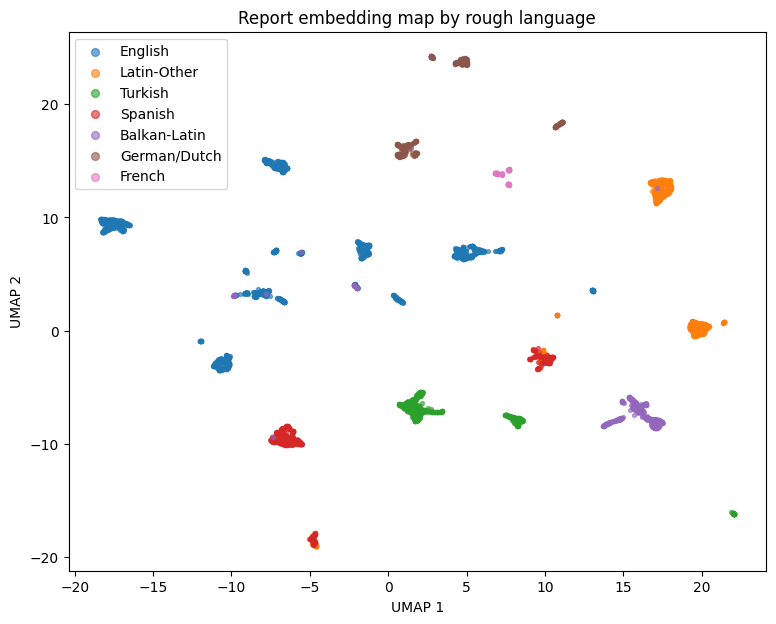

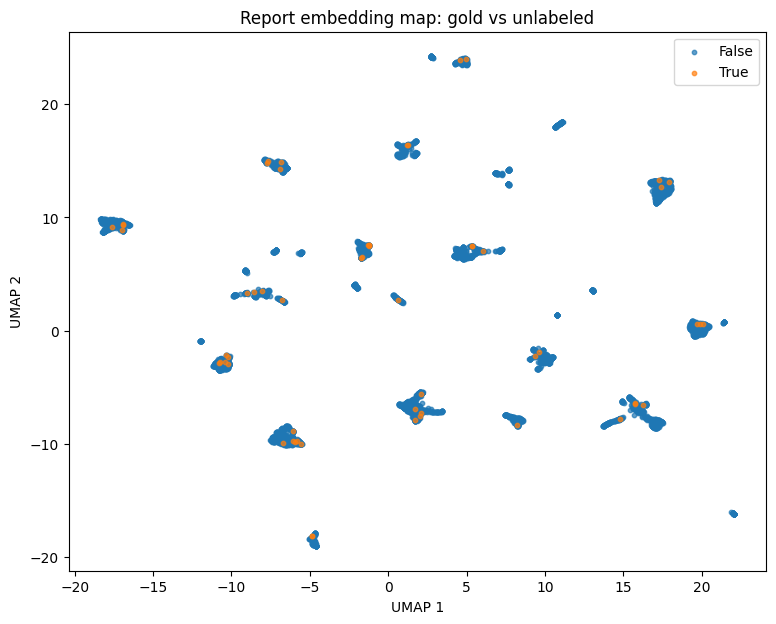

In [22]:
if package_status.get("umap") is not None:
    import umap
    reducer = umap.UMAP(
        n_neighbors=30,
        min_dist=0.1,
        metric="cosine",
        random_state=SEED
    )
    X_2d = reducer.fit_transform(X_text)
    embedding_method = "UMAP"
else:
    X_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_text)
    embedding_method = "PCA"

plot_df = pd.DataFrame({
    "x": X_2d[:,0],
    "y": X_2d[:,1],
    "language": rpt["language"].values,
    "is_gold": rpt["is_gold"].values,
})

plt.figure(figsize=(9,7))
for lang in plot_df["language"].value_counts().index:
    m = plot_df["language"].eq(lang)
    plt.scatter(plot_df.loc[m,"x"], plot_df.loc[m,"y"], s=8, alpha=0.6, label=lang)
plt.xlabel(f"{embedding_method} 1")
plt.ylabel(f"{embedding_method} 2")
plt.title("Report embedding map by rough language")
plt.legend(markerscale=2)
plt.show()

plt.figure(figsize=(9,7))
for flag in [False, True]:
    m = plot_df["is_gold"].eq(flag)
    plt.scatter(plot_df.loc[m,"x"], plot_df.loc[m,"y"], s=10, alpha=0.7, label=str(flag))
plt.xlabel(f"{embedding_method} 1")
plt.ylabel(f"{embedding_method} 2")
plt.title("Report embedding map: gold vs unlabeled")
plt.legend()
plt.show()

## 18. Text cluster discovery and representative reports

In [23]:
cluster_candidates = [8, 12, 16, 24]
cluster_scores = []

sample_for_sil = np.arange(len(X_text))
if len(sample_for_sil) > 2500:
    sample_for_sil = rng.choice(sample_for_sil, 2500, replace=False)

for k in cluster_candidates:
    km = MiniBatchKMeans(
        n_clusters=k,
        random_state=SEED,
        batch_size=512,
        n_init="auto"
    )
    labels = km.fit_predict(X_text)
    try:
        sil = silhouette_score(X_text[sample_for_sil], labels[sample_for_sil], metric="euclidean")
    except Exception:
        sil = np.nan
    cluster_scores.append((k,sil))

display(pd.DataFrame(cluster_scores, columns=["k","silhouette"]))

valid = [(k,s) for k,s in cluster_scores if np.isfinite(s)]
BEST_K = max(valid, key=lambda x:x[1])[0] if valid else 12

km = MiniBatchKMeans(
    n_clusters=BEST_K,
    random_state=SEED,
    batch_size=512,
    n_init="auto"
)
text_cluster = km.fit_predict(X_text)
rpt["text_cluster"] = text_cluster

display(pd.crosstab(rpt["text_cluster"], rpt["language"]))

# Representative report = closest document to each cluster center.
for c in sorted(np.unique(text_cluster)):
    members = np.where(text_cluster == c)[0]
    center = km.cluster_centers_[c]
    d = np.linalg.norm(X_text[members] - center, axis=1)
    i = members[np.argmin(d)]
    print("\n" + "="*100)
    print("CLUSTER", c, "| size", len(members),
          "| language mode", rpt.loc[members,"language"].mode().iloc[0])
    print(train.iloc[i]["Report"][:1200].replace("\n"," "))

,k,silhouette
0,8,0.228172
1,12,0.309091
2,16,0.365012
3,24,0.313916


language,Balkan-Latin,English,French,German/Dutch,Latin-Other,Spanish,Turkish
text_cluster,,,,,,,
0,0,346,0,0,0,0,0
1,0,0,0,0,84,142,0
2,23,669,0,0,0,0,0
3,0,0,0,0,0,0,372
4,0,0,0,0,220,0,0
5,406,0,0,0,0,0,0
6,0,0,0,0,0,0,174
7,0,292,0,0,0,0,0
8,0,0,0,257,5,0,0



CLUSTER 0 | size 346 | language mode English
Exam Type: MRI KNEE LEFT WO CONTRAST Exam Date and Time: [DATE] [TIME] Indication: Pain in the left kidney; right knee pain for 4 weeks, no injury. Comparison: No relevant prior studies available for comparison.  TECHNIQUE: MRI of the left knee was performed on a 1.5 Tesla system with a dedicated knee coil in three planes (axial, sagittal, and coronal), using a standard non-contrast protocol.  FINDINGS: OSSEOUS STRUCTURES: Alignment is anatomic. No acute fracture or bone bruise. Background marrow signal is normal without infiltrative marrow process. No aggressive osseous lesions.   JOINT SPACE: Trace joint effusion. No intra-articular bodies. Trace Baker's cyst.  MEDIAL COMPARTMENT: Medial meniscus: Normal in morphology and signal. Medial compartment cartilage: No focal cartilage defects.  LATERAL COMPARTMENT: Lateral meniscus: Normal in morphology and signal. Lateral compartment cartilage: Cartilage heterogeneity and fissuring along the we

# 19. Gold-selection adversarial validation using only report embeddings

This checks whether the *semantic/style space of the reports themselves* distinguishes the 58 gold studies from the rest.

In [24]:
y_gold = train["is_gold"].astype(int).values

text_clf = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    C=0.2,
    solver="liblinear",
    random_state=SEED
)

text_oof = cross_val_predict(
    text_clf,
    X_text,
    y_gold,
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    method="predict_proba"
)[:,1]

print("Text-only gold-selection OOF AUC:",
      round(roc_auc_score(y_gold, text_oof),4))

Text-only gold-selection OOF AUC: 0.6703


# 20. Cleanlab Datalab when available; kNN fallback otherwise

Cleanlab can use embeddings to look for:
- outliers,
- near duplicates,
- non-IID structure.

If Cleanlab is not installed, we calculate transparent nearest-neighbor scores directly.

In [25]:
issue_table = pd.DataFrame({
    "StudyInstanceUID": train["StudyInstanceUID"].values
})

if package_status.get("cleanlab") is not None:
    try:
        from cleanlab import Datalab

        lab = Datalab(data={"id": np.arange(len(train))})
        lab.find_issues(
            features=X_text,
            issue_types={
                "outlier": {},
                "near_duplicate": {},
                "non_iid": {},
            }
        )

        outlier_issues = lab.get_issues("outlier")
        duplicate_issues = lab.get_issues("near_duplicate")

        issue_table["text_outlier_score"] = outlier_issues["outlier_score"].values
        issue_table["text_near_duplicate_score"] = duplicate_issues["near_duplicate_score"].values

        print("Cleanlab Datalab completed.")
    except Exception as e:
        print("Cleanlab failed; using kNN fallback:", type(e).__name__, str(e)[:200])
        package_status["cleanlab"] = None

if package_status.get("cleanlab") is None:
    knn = NearestNeighbors(n_neighbors=11, metric="cosine", n_jobs=-1).fit(X_text)
    d, j = knn.kneighbors(X_text)
    issue_table["text_nn_distance"] = d[:,1]
    issue_table["text_knn10_mean_distance"] = d[:,1:].mean(axis=1)
    issue_table["text_outlier_score"] = 1 / (1 + issue_table["text_knn10_mean_distance"])
    issue_table["text_near_duplicate_score"] = 1 / (1 + issue_table["text_nn_distance"])

display(issue_table.sort_values("text_outlier_score").head(30))

,StudyInstanceUID,text_nn_distance,text_knn10_mean_distance,text_outlier_score,text_near_duplicate_score
3610,1.2.826.0.1.3680043.8.498.78646473961447523033955716877524794707,0.365874,0.389534,0.719666,0.732132
2863,1.2.826.0.1.3680043.8.498.58811528407321581206563412079643094538,0.242538,0.380315,0.724472,0.804804
4367,1.2.826.0.1.3680043.8.498.99052905406751383674032587504235261874,0.252103,0.338160,0.747295,0.798657
786,1.2.826.0.1.3680043.8.498.12285177271228289867211553575739205132,0.279801,0.329687,0.752056,0.781371
2800,1.2.826.0.1.3680043.8.498.56939860329243258146102948466697018543,0.251499,0.327280,0.753421,0.799042
3926,1.2.826.0.1.3680043.8.498.87253761427012478584873622994909841751,0.226280,0.308970,0.763960,0.815474
1454,1.2.826.0.1.3680043.8.498.20640858366001462094044810443654811785,0.274788,0.308093,0.764472,0.784444
1773,1.2.826.0.1.3680043.8.498.28944156754203202831026290463520445489,0.258237,0.306513,0.765396,0.794763
89,1.2.826.0.1.3680043.8.498.10252121617380434672930525780360219531,0.267164,0.306038,0.765674,0.789164
3030,1.2.826.0.1.3680043.8.498.63726512375511246975989322174096818969,0.209489,0.303057,0.767426,0.826796


# 21. Sampled full-stack geometry audit

One-header-per-series inventory cannot detect irregular slice spacing inside a stack.

We therefore sample complete series and inspect every slice header.

Flags:
- missing spatial position,
- duplicate physical position,
- irregular inter-slice spacing,
- missing orientation,
- spatial order vs `InstanceNumber` disagreement.

Increase `N_STACK_QC` if runtime permits.

In [26]:
N_STACK_QC = 600

def spatial_coordinate(ds):
    try:
        ori = np.asarray([float(x) for x in ds.ImageOrientationPatient])
        pos = np.asarray([float(x) for x in ds.ImagePositionPatient])
        normal = np.cross(ori[:3], ori[3:])
        return float(np.dot(pos, normal))
    except Exception:
        return np.nan

qc_sample = train_inv.sample(min(N_STACK_QC, len(train_inv)), random_state=SEED)

stack_rows = []

for _, r in qc_sample.iterrows():
    folder = DATA_DIR / "train_series" / str(r["StudyInstanceUID"]) / str(r["SeriesInstanceUID"])
    files = [p for p in folder.iterdir() if p.is_file()]

    positions=[]
    instances=[]
    orientations=[]

    for f in files:
        try:
            ds = pydicom.dcmread(str(f), stop_before_pixels=True)
            positions.append(spatial_coordinate(ds))
            instances.append(safe_float(getattr(ds,"InstanceNumber",np.nan)))
            orientations.append(safe_mv(getattr(ds,"ImageOrientationPatient","")))
        except Exception:
            positions.append(np.nan)
            instances.append(np.nan)
            orientations.append("")

    p = np.asarray(positions, dtype=float)
    valid = np.isfinite(p)

    unique_pos = len(np.unique(np.round(p[valid],6))) if valid.any() else 0
    dup_pos = int(valid.sum() - unique_pos)

    if valid.sum() >= 3:
        sorted_p = np.sort(p[valid])
        gaps = np.diff(sorted_p)
        gap_med = np.median(np.abs(gaps))
        gap_cv = np.std(gaps) / (abs(np.mean(gaps)) + 1e-8)
        gap_rel_mad = (
            np.median(np.abs(gaps - np.median(gaps))) /
            (abs(np.median(gaps)) + 1e-8)
        )
    else:
        gap_med = gap_cv = gap_rel_mad = np.nan

    inst = np.asarray(instances, dtype=float)
    both = valid & np.isfinite(inst)

    spearman = np.nan
    if both.sum() >= 3:
        spearman = stats.spearmanr(p[both], inst[both]).statistic

    stack_rows.append({
        "StudyInstanceUID": r["StudyInstanceUID"],
        "SeriesInstanceUID": r["SeriesInstanceUID"],
        "Plane": r["Anatomical_Plane"],
        "n_files": len(files),
        "position_available_pct": 100*valid.mean() if len(valid) else 0,
        "duplicate_positions": dup_pos,
        "orientation_variants": len(set(o for o in orientations if o)),
        "median_spatial_gap": gap_med,
        "gap_cv": gap_cv,
        "gap_relative_mad": gap_rel_mad,
        "position_instance_spearman": spearman,
    })

stack_qc = pd.DataFrame(stack_rows)
display(stack_qc.describe(include="all"))

print("\nMost irregular spatial gaps:")
display(stack_qc.sort_values("gap_relative_mad", ascending=False).head(30))

,StudyInstanceUID,SeriesInstanceUID,Plane,n_files,position_available_pct,duplicate_positions,orientation_variants,median_spatial_gap,gap_cv,gap_relative_mad,position_instance_spearman
count,600,600,600,600.000000,600.0,600.0,600.000000,600.000000,6.000000e+02,6.000000e+02,600.000000
unique,564,600,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,1.2.826.0.1.3680043.8.498.13152690996267297597178587721720788387,1.2.826.0.1.3680043.8.498.11857156675146631276334353675579164655,Coronal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,3,1,235,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,34.648333,100.0,0.0,1.958333,3.680832,1.246025e-05,4.539839e-06,0.263333
std,NaN,NaN,NaN,31.270183,0.0,0.0,3.407729,0.939395,2.280361e-05,1.246773e-05,0.965510
min,NaN,NaN,NaN,11.000000,100.0,0.0,1.000000,0.399995,9.605457e-13,0.000000e+00,-1.000000
25%,NaN,NaN,NaN,25.000000,100.0,0.0,1.000000,3.300000,4.528938e-07,4.659468e-08,-1.000000
50%,NaN,NaN,NaN,30.000000,100.0,0.0,1.000000,3.500000,8.581098e-07,2.747640e-07,1.000000
75%,NaN,NaN,NaN,34.000000,100.0,0.0,1.000000,4.399998,1.282066e-05,2.086379e-06,1.000000



Most irregular spatial gaps:


,StudyInstanceUID,SeriesInstanceUID,Plane,n_files,position_available_pct,duplicate_positions,orientation_variants,median_spatial_gap,gap_cv,gap_relative_mad,position_instance_spearman
552,1.2.826.0.1.3680043.8.498.93728117237268000947508816107096388086,1.2.826.0.1.3680043.8.498.15644146908239619120472597058200885924,Axial,144,100.0,0,1,0.599980,0.000147,0.000152,-1.0
512,1.2.826.0.1.3680043.8.498.41640481150213029810772014344448781554,1.2.826.0.1.3680043.8.498.97330234840707787563422878066979815132,Sagittal,22,100.0,0,7,4.500016,0.000095,0.000109,-1.0
116,1.2.826.0.1.3680043.8.498.64283618749539713756220539395944025878,1.2.826.0.1.3680043.8.498.83940835335605839007009645522186343158,Sagittal,33,100.0,0,1,3.299988,0.000109,0.000090,1.0
561,1.2.826.0.1.3680043.8.498.93054327536380380487760790221613186305,1.2.826.0.1.3680043.8.498.76370408169428562661092487428972211498,Axial,160,100.0,0,1,0.599996,0.000079,0.000082,-1.0
542,1.2.826.0.1.3680043.8.498.41854610297797849683195403204758363476,1.2.826.0.1.3680043.8.498.80541835872125771619954584436948165755,Axial,160,100.0,0,1,0.599989,0.000081,0.000067,-1.0
308,1.2.826.0.1.3680043.8.498.55930031395651221279170435293900769500,1.2.826.0.1.3680043.8.498.56537216409438351368489711785653711807,Sagittal,35,100.0,0,1,3.299961,0.000097,0.000062,1.0
557,1.2.826.0.1.3680043.8.498.11647595587705638372290862475518195181,1.2.826.0.1.3680043.8.498.59907782726032629195011270876548111559,Sagittal,40,100.0,0,1,3.300178,0.000099,0.000056,-1.0
63,1.2.826.0.1.3680043.8.498.10855290714402117092990651362697310270,1.2.826.0.1.3680043.8.498.94978801886429346268220177480964043900,Sagittal,23,100.0,0,6,4.500100,0.000069,0.000046,-1.0
77,1.2.826.0.1.3680043.8.498.95918254432056542701730614049432316728,1.2.826.0.1.3680043.8.498.56446168128694689940701884752213832711,Sagittal,32,100.0,0,1,3.300064,0.000071,0.000037,-1.0
134,1.2.826.0.1.3680043.8.498.85397267100597758920280635204297906286,1.2.826.0.1.3680043.8.498.70350327198921407407933322037851873412,Sagittal,19,100.0,0,8,4.500041,0.000048,0.000036,-1.0


# 22. Representative-slice image-quality audit

This is not a diagnostic-image quality score.  
It is a **data-pipeline QC** tool to find unusual/blank/cropped/very low-contrast series.

Increase `N_IMAGE_QC` if desired.

,StudyInstanceUID,SeriesInstanceUID,Plane,Manufacturer,Fluid,entropy,edge_energy,foreground_fraction,mean_norm,std_norm,low_clip_fraction,high_clip_fraction
count,1500,1500,1500,1500,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
unique,1277,1500,3,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,1.2.826.0.1.3680043.8.498.90466423642678253933409966898120881010,1.2.826.0.1.3680043.8.498.10083122843267350812887063988960514349,Sagittal,Siemens Healthineers,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,4,1,562,351,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,0.575333,4.759241,0.219332,0.663573,0.286463,0.259748,0.094184,0.010144
std,NaN,NaN,NaN,NaN,0.494457,0.643921,0.068250,0.152625,0.092430,0.050911,0.116256,0.001156
min,NaN,NaN,NaN,NaN,0.000000,1.290456,0.059537,0.117233,0.065446,0.135090,0.010010,0.010001
25%,NaN,NaN,NaN,NaN,0.000000,4.421262,0.172060,0.565365,0.217290,0.220378,0.017813,0.010039
50%,NaN,NaN,NaN,NaN,1.000000,4.919015,0.212273,0.691447,0.287037,0.256970,0.041759,0.010075
75%,NaN,NaN,NaN,NaN,1.000000,5.231652,0.263338,0.772037,0.350781,0.299344,0.126931,0.010150


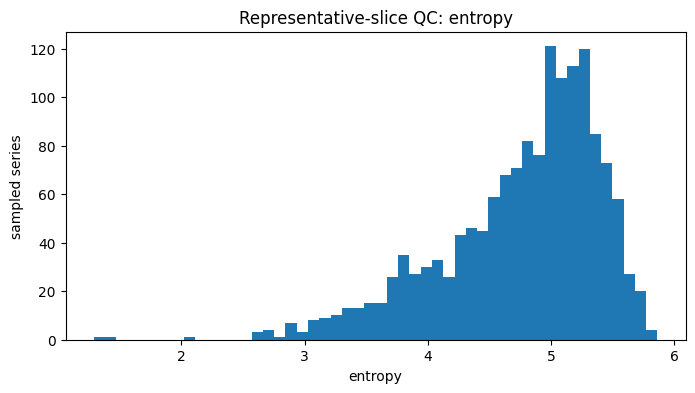

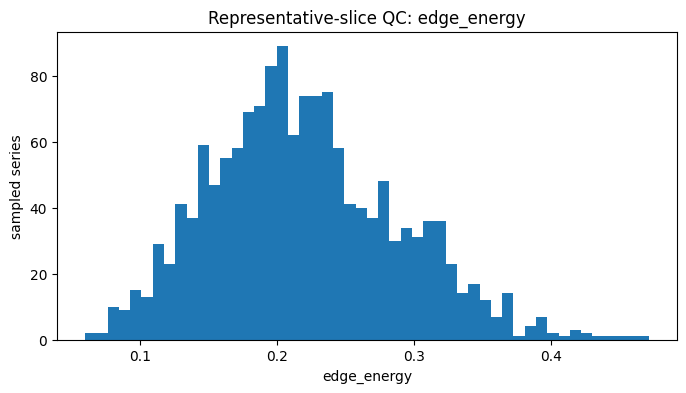

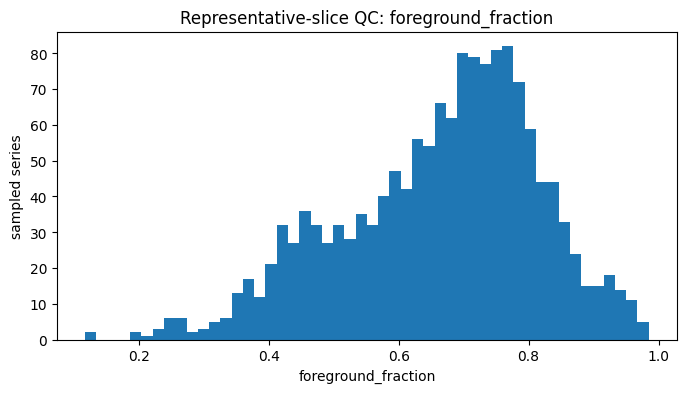

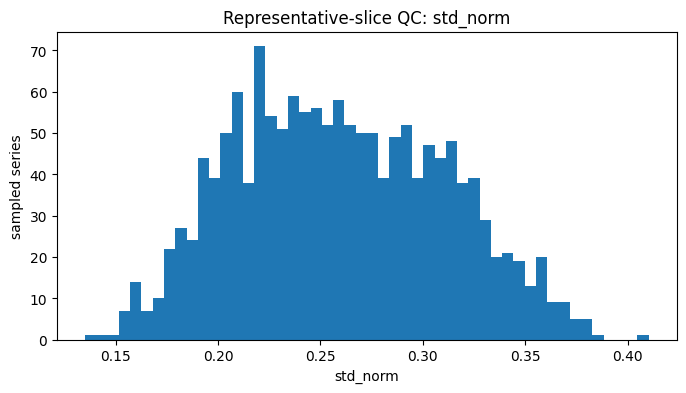

In [27]:
N_IMAGE_QC = 1500

def order_key(path):
    try:
        ds = pydicom.dcmread(str(path), stop_before_pixels=True)
        z = spatial_coordinate(ds)
        if np.isfinite(z):
            return (0,z)
        inst = safe_float(getattr(ds,"InstanceNumber",np.nan))
        if np.isfinite(inst):
            return (1,inst)
    except Exception:
        pass
    return (2,path.name)

def normalize_01(img):
    img = np.asarray(img, dtype=np.float32)
    lo,hi = np.percentile(img,[1,99])
    if hi <= lo:
        return np.zeros_like(img)
    img = np.clip(img,lo,hi)
    return (img-lo)/(hi-lo)

def entropy01(img, bins=64):
    hist,_ = np.histogram(img[np.isfinite(img)], bins=bins, range=(0,1), density=False)
    p = hist.astype(float)
    p = p[p>0]
    p /= p.sum()
    return float(-(p*np.log2(p)).sum())

image_sample = train_inv.sample(min(N_IMAGE_QC, len(train_inv)), random_state=SEED)
quality_rows=[]

for _,r in image_sample.iterrows():
    folder = DATA_DIR / "train_series" / str(r["StudyInstanceUID"]) / str(r["SeriesInstanceUID"])
    files = sorted([p for p in folder.iterdir() if p.is_file()], key=order_key)
    if not files:
        continue
    f = files[len(files)//2]

    try:
        ds = pydicom.dcmread(str(f))
        img = ds.pixel_array.astype(np.float32)
        slope = safe_float(getattr(ds,"RescaleSlope",1.0))
        intercept = safe_float(getattr(ds,"RescaleIntercept",0.0))
        if not np.isfinite(slope): slope=1.0
        if not np.isfinite(intercept): intercept=0.0
        img = img*slope+intercept

        if getattr(ds,"PhotometricInterpretation","") == "MONOCHROME1":
            img = img.max()-img

        x = normalize_01(img)
        gx = sobel(x, axis=0)
        gy = sobel(x, axis=1)
        edge_energy = float(np.mean(np.sqrt(gx*gx+gy*gy)))

        # Background is often dark in MRI. This only estimates occupied image fraction.
        foreground = float((x > 0.05).mean())

        quality_rows.append({
            "StudyInstanceUID": r["StudyInstanceUID"],
            "SeriesInstanceUID": r["SeriesInstanceUID"],
            "Plane": r["Anatomical_Plane"],
            "Manufacturer": r["Manufacturer"],
            "Fluid": r["Fluid_Sensitive"],
            "entropy": entropy01(x),
            "edge_energy": edge_energy,
            "foreground_fraction": foreground,
            "mean_norm": float(x.mean()),
            "std_norm": float(x.std()),
            "low_clip_fraction": float((x <= 0.001).mean()),
            "high_clip_fraction": float((x >= 0.999).mean()),
        })
    except Exception:
        pass

image_qc = pd.DataFrame(quality_rows)
display(image_qc.describe(include="all"))

for col in ["entropy","edge_energy","foreground_fraction","std_norm"]:
    plt.figure(figsize=(8,4))
    plt.hist(image_qc[col].dropna(), bins=50)
    plt.xlabel(col)
    plt.ylabel("sampled series")
    plt.title(f"Representative-slice QC: {col}")
    plt.show()

## 23. Detect representative-slice QC outliers

In [28]:
for col in ["entropy","edge_energy","foreground_fraction","std_norm"]:
    image_qc[f"rz_{col}"] = robust_z(image_qc[col])

iq_rz = [c for c in image_qc if c.startswith("rz_")]
image_qc["image_qc_outlier_score"] = image_qc[iq_rz].abs().max(axis=1)

display(
    image_qc.sort_values("image_qc_outlier_score", ascending=False).head(40)
)

,StudyInstanceUID,SeriesInstanceUID,Plane,Manufacturer,Fluid,entropy,edge_energy,foreground_fraction,mean_norm,std_norm,low_clip_fraction,high_clip_fraction,rz_entropy,rz_edge_energy,rz_foreground_fraction,rz_std_norm,image_qc_outlier_score
1272,1.2.826.0.1.3680043.8.498.35015675197378142698488944856288804597,1.2.826.0.1.3680043.8.498.26190161195183929804521180373336032297,Axial,Philips,0,1.290456,0.116259,0.117233,0.065446,0.209664,0.825211,0.010193,-6.526178,-1.434297,-4.048236,-0.821728,6.526178
305,1.2.826.0.1.3680043.8.498.27319908980978184820438244981035567211,1.2.826.0.1.3680043.8.498.12715211551947485275927848748971469433,Axial,Philips,0,1.434504,0.104596,0.132019,0.077385,0.222482,0.787506,0.010162,-6.267100,-1.608524,-3.943995,-0.599076,6.267100
147,1.2.826.0.1.3680043.8.498.12273356591019341319494035708698721367,1.2.826.0.1.3680043.8.498.82244179458701501947613155384596080837,Axial,Philips,0,2.026989,0.151441,0.197281,0.098803,0.233935,0.701279,0.010208,-5.201479,-0.908733,-3.483896,-0.400132,5.201479
364,1.2.826.0.1.3680043.8.498.63126604639589769235241216875934773992,1.2.826.0.1.3680043.8.498.62951922811318377360525753451250565855,Axial,GE MEDICAL SYSTEMS,1,2.604745,0.088350,0.266319,0.070238,0.161233,0.090782,0.010181,-4.162352,-1.851209,-2.997172,-1.662986,4.162352
249,1.2.826.0.1.3680043.8.498.25635522141852534580088120697977308505,1.2.826.0.1.3680043.8.498.57637846215643520635274142834789344702,Axial,Philips,1,2.652334,0.083659,0.293910,0.156475,0.259931,0.370498,0.010014,-4.076759,-1.921295,-2.802657,0.051439,4.076759
1209,1.2.826.0.1.3680043.8.498.10190506315646895064803936408630113507,1.2.826.0.1.3680043.8.498.10176379852205420311211715017017353604,Axial,Philips Medical Systems,1,2.653992,0.074576,0.293789,0.179549,0.300064,0.672490,0.010537,-4.073779,-2.056980,-2.803508,0.748554,4.073779
1318,1.2.826.0.1.3680043.8.498.87465202523430400780596885230492167155,1.2.826.0.1.3680043.8.498.14534693076291100409998862601428211851,Axial,Philips,1,2.663447,0.133581,0.277306,0.127485,0.236175,0.659988,0.010368,-4.056772,-1.175537,-2.919718,-0.361222,4.056772
1026,1.2.826.0.1.3680043.8.498.48918090379630186340047006216221526186,1.2.826.0.1.3680043.8.498.88137516751686219550286653559130720190,Axial,Siemens Healthineers,1,2.667145,0.080832,0.231814,0.076919,0.178406,0.099752,0.010078,-4.050122,-1.963523,-3.240436,-1.364681,4.050122
1115,1.2.826.0.1.3680043.8.498.11040296449332764126530525726037541310,1.2.826.0.1.3680043.8.498.72869894823761377178626980069986100075,Axial,Siemens Healthineers,1,2.670469,0.082766,0.195376,0.094586,0.210694,0.090382,0.010013,-4.044143,-1.934637,-3.497326,-0.803833,4.044143
552,1.2.826.0.1.3680043.8.498.93728117237268000947508816107096388086,1.2.826.0.1.3680043.8.498.15644146908239619120472597058200885924,Axial,Siemens Healthineers,1,2.753576,0.092077,0.211782,0.076314,0.176970,0.162893,0.010026,-3.894671,-1.795533,-3.381661,-1.389631,3.894671


# 24. Domain clusters for future fold design

We cluster acquisition features to expose latent scanner/protocol domains.

These clusters should later be inspected during cross-validation so one fold does not accidentally contain only one acquisition family.

In [29]:
domain_num = [
    "field_strength","median_slices","max_slices",
    "median_fov","median_inplane","median_anisotropy",
    "median_thickness","n_series","n_fluid",
    "n_sagittal","n_coronal","n_axial"
]

D = study_domain[["StudyInstanceUID","manufacturer"] + domain_num].copy()
for c in domain_num:
    D[c] = pd.to_numeric(D[c], errors="coerce")
    D[c] = D[c].fillna(D[c].median())

dom_pre = ColumnTransformer([
    ("num", StandardScaler(), domain_num),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), ["manufacturer"])
])
Z = dom_pre.fit_transform(D)

N_DOMAIN_CLUSTERS = 12
dom_km = MiniBatchKMeans(
    n_clusters=N_DOMAIN_CLUSTERS,
    random_state=SEED,
    n_init="auto",
    batch_size=512
)
D["domain_cluster"] = dom_km.fit_predict(Z)

display(pd.crosstab(D["domain_cluster"], D["manufacturer"]))
display(D["domain_cluster"].value_counts().sort_index().to_frame("studies"))

manufacturer,CANON_MEC,FUJIFILM Healthcare Corporation,GE MEDICAL SYSTEMS,GEHC,Hitachi Medical Corporation,Philips,Philips Healthcare,Philips Medical Systems,SIEMENS,Siemens,Siemens Healthineers,TOSHIBA
domain_cluster,,,,,,,,,,,,
0,0,14,260,31,4,3,0,132,17,0,147,9
1,2,2,6,0,0,220,1,15,91,8,3,0
2,0,0,180,0,0,29,11,5,18,0,5,0
3,0,0,34,5,0,159,72,23,221,0,2,0
4,17,0,0,0,0,7,3,212,9,4,187,0
5,0,0,0,0,0,0,0,85,0,0,255,0
6,0,0,0,0,0,1,0,0,106,2,346,0
7,0,0,108,0,0,0,0,1,0,0,2,0
8,0,0,0,0,0,10,0,225,0,80,71,0


,studies
domain_cluster,
0,617
1,348
2,248
3,516
4,439
5,340
6,455
7,111
8,386


# 25. Gold coverage across discovered domains

A good gold diagnostic set should ideally touch many important acquisition and report domains.

This does **not** imply we should force identical percentages—the 58 studies were not necessarily sampled randomly.

In [30]:
gold_domain = (
    train[["StudyInstanceUID","is_gold"]]
    .merge(D[["StudyInstanceUID","domain_cluster"]], on="StudyInstanceUID", how="left")
    .merge(rpt[["StudyInstanceUID","language","text_cluster"]], on="StudyInstanceUID", how="left")
)

print("Acquisition-domain coverage:")
display(pd.crosstab(gold_domain["domain_cluster"], gold_domain["is_gold"]))

print("\nText-cluster coverage:")
display(pd.crosstab(gold_domain["text_cluster"], gold_domain["is_gold"]))

print("\nLanguage coverage:")
display(pd.crosstab(gold_domain["language"], gold_domain["is_gold"]))

Acquisition-domain coverage:


is_gold,False,True
domain_cluster,,
0,613,4
1,341,7
2,244,4
3,510,6
4,434,5
5,337,3
6,449,6
7,110,1
8,382,4



Text-cluster coverage:


is_gold,False,True
text_cluster,,
0,342,4
1,224,2
2,682,10
3,367,5
4,217,3
5,402,4
6,173,1
7,289,3
8,260,2



Language coverage:


is_gold,False,True
language,,
Balkan-Latin,441,5
English,1723,28
French,71,0
German/Dutch,364,3
Latin-Other,686,8
Spanish,524,8
Turkish,540,6


# 26. Multilabel gold-set diagnostics

We add:
- label cardinality,
- Jaccard similarity between gold studies,
- rare label-combination count.

This will later matter for fold construction.

In [31]:
gold = train[train["is_gold"]].copy()
Y = gold[TARGETS].astype(int).values
gold["label_cardinality"] = Y.sum(axis=1)

combos = pd.Series(
    ["".join(map(str,row)) for row in Y],
    index=gold.index
)
print("Unique 12-label combinations among 58 gold studies:", combos.nunique())
display(combos.value_counts().head(20).to_frame("count"))

# Pairwise Jaccard among positive-label sets.
jacc=[]
for i in range(len(Y)):
    for j in range(i+1,len(Y)):
        inter = np.logical_and(Y[i],Y[j]).sum()
        union = np.logical_or(Y[i],Y[j]).sum()
        jacc.append(inter/union if union else 1.0)

print("Pairwise label-set Jaccard summary:")
display(pd.Series(jacc).describe().to_frame("jaccard"))

Unique 12-label combinations among 58 gold studies: 54


,count
101111111100,2
101100011011,2
010000000000,2
101000010000,2
001010101000,1
000000110000,1
000000011010,1
100101010000,1
001110110001,1
010000000010,1


Pairwise label-set Jaccard summary:


,jaccard
count,1653.000000
mean,0.223948
std,0.197246
min,0.000000
25%,0.000000
50%,0.200000
75%,0.333333
max,1.000000


# 27. Final risk dashboard

This cell turns the EDA into concrete modeling decisions.

The flags are deliberately simple and interpretable.

In [32]:
risk_rows = []

# Gold selection
risk_rows.append({
    "area": "Gold representativeness",
    "metric": "metadata adversarial AUC",
    "value": float(auc),
    "flag": "HIGH" if auc >= 0.75 else ("MEDIUM" if auc >= 0.65 else "LOW"),
    "implication": "Use gold set as diagnostic, not naive population estimate, if distinguishable."
})

text_auc = roc_auc_score(y_gold, text_oof)
risk_rows.append({
    "area": "Gold report-selection bias",
    "metric": "text adversarial AUC",
    "value": float(text_auc),
    "flag": "HIGH" if text_auc >= 0.75 else ("MEDIUM" if text_auc >= 0.65 else "LOW"),
    "implication": "NLP validation may be optimistic/pessimistic across language/template domains."
})

risk_rows.append({
    "area": "Report duplication",
    "metric": "NN similarity >= 0.98",
    "value": int((near["nearest_similarity"] >= 0.98).sum()),
    "flag": "MEDIUM" if (near["nearest_similarity"] >= 0.98).sum() > 50 else "LOW",
    "implication": "Group similar templates when designing NLP validation."
})

risk_rows.append({
    "area": "MRI geometry",
    "metric": "sampled stacks with duplicate positions",
    "value": int((stack_qc["duplicate_positions"] > 0).sum()),
    "flag": "MEDIUM" if (stack_qc["duplicate_positions"] > 0).any() else "LOW",
    "implication": "Loader must use physical ordering and handle duplicated/irregular positions."
})

risk_rows.append({
    "area": "MRI acquisition heterogeneity",
    "metric": "series physical outliers |robust z|>5",
    "value": int((train_inv["physical_outlier_score"] > 5).sum()),
    "flag": "HIGH" if (train_inv["physical_outlier_score"] > 5).sum() > 100 else "MEDIUM",
    "implication": "Prefer physical-space-aware preprocessing over blind resize."
})

risk_dashboard = pd.DataFrame(risk_rows)
display(risk_dashboard)

,area,metric,value,flag,implication
0,Gold representativeness,metadata adversarial AUC,0.559780,LOW,"Use gold set as diagnostic, not naive population estimate, if distinguishable."
1,Gold report-selection bias,text adversarial AUC,0.670251,MEDIUM,NLP validation may be optimistic/pessimistic across language/template domains.
2,Report duplication,NN similarity >= 0.98,277.000000,MEDIUM,Group similar templates when designing NLP validation.
3,MRI geometry,sampled stacks with duplicate positions,0.000000,LOW,Loader must use physical ordering and handle duplicated/irregular positions.
4,MRI acquisition heterogeneity,series physical outliers |robust z|>5,3263.000000,HIGH,Prefer physical-space-aware preprocessing over blind resize.


# 28. Save advanced EDA artifacts

These files are designed to feed the next decisions and later error analysis.

In [33]:
OUT = Path("/kaggle/working")

train_inv.to_csv(OUT / "rsna_advanced_series_inventory_train.csv", index=False)
study.to_csv(OUT / "rsna_advanced_study_features.csv", index=False)
rpt.drop(columns=["Report"]).to_csv(OUT / "rsna_report_eda_features.csv", index=False)
near.to_csv(OUT / "rsna_report_nearest_neighbors.csv", index=False)
issue_table.to_csv(OUT / "rsna_text_issue_scores.csv", index=False)
stack_qc.to_csv(OUT / "rsna_stack_geometry_qc_sample.csv", index=False)
image_qc.to_csv(OUT / "rsna_image_qc_sample.csv", index=False)
D.to_csv(OUT / "rsna_domain_clusters.csv", index=False)
risk_dashboard.to_csv(OUT / "rsna_eda_risk_dashboard.csv", index=False)
shift_numeric.to_csv(OUT / "rsna_gold_unlabeled_numeric_shift.csv", index=False)

print("Saved advanced EDA artifacts to", OUT)

Saved advanced EDA artifacts to /kaggle/working


# 29. What to send back after running

The highest-value outputs are:

1. `rsna_eda_risk_dashboard.csv`
2. `rsna_gold_unlabeled_numeric_shift.csv`
3. `rsna_domain_clusters.csv`
4. `rsna_report_nearest_neighbors.csv`
5. `rsna_stack_geometry_qc_sample.csv`
6. `rsna_image_qc_sample.csv`
7. the executed notebook

With those outputs we can decide:

- whether the 58 gold studies are distributionally biased,
- how to split folds,
- whether report-template grouping is necessary,
- which MRI acquisition domains need stratification,
- whether a physical-space crop/resample is needed,
- how aggressive image normalization can be,
- and whether we are ready to start the clinical NLP pseudo-label engine.